In [1]:
from quantfolio import add

# Taller B1-T1

## Minimal `src/` → notebook example

The function lives in `src/quantfolio/example.py` and is re-exported by the package in `src/quantfolio/__init__.py`. The editable install puts `src/` on `sys.path`, so the notebook can import it directly.

In [2]:
add(2, 3)

5

## NVIDIA price smoke test

`get_latest_nvidia_stock` lives in `tests/test_example.py` and pulls recent daily `NVDA` prices through `yfinance`. This verifies live market-data access and plotting from inside the scaffold (an environment smoke test, not part of the `quantfolio` package).

In [3]:
import importlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt

repo_root = Path.cwd().resolve()
while not (repo_root / "pyproject.toml").is_file() and repo_root != repo_root.parent:
    repo_root = repo_root.parent

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

get_latest_nvidia_stock = importlib.import_module("tests.test_example").get_latest_nvidia_stock

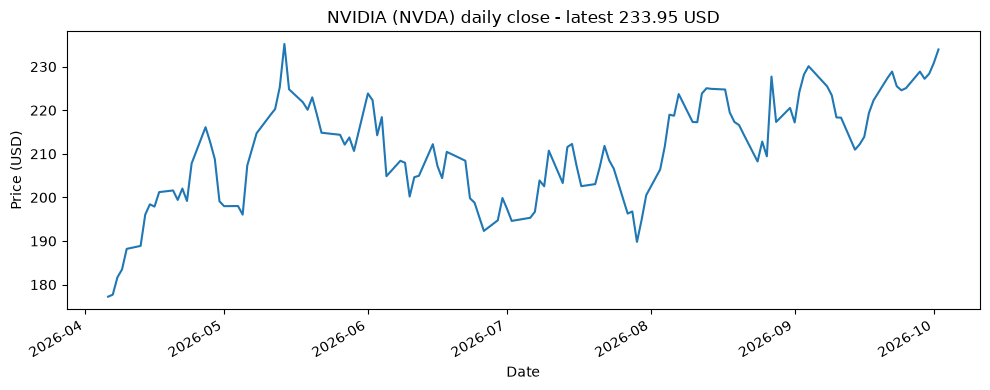

In [4]:
nvidia = get_latest_nvidia_stock(period="6mo")
latest_close = nvidia["Close"].iloc[-1]

ax = nvidia["Close"].plot(
    title=f"NVIDIA (NVDA) daily close - latest {latest_close:.2f} USD",
    xlabel="Date",
    ylabel="Price (USD)",
    figsize=(10, 4),
)
ax.figure.tight_layout()
plt.show()